# Crosstalk-aware conjugate gradient against conjugate gradient on the crosstalk device

**Question:** On a device whose pixels leak into each other, what does a conjugate-gradient optimiser that has the crosstalk kernel in its model (M13) win back over the same optimiser on the ideal model (M10)?

- Level: 3, state of the art. Method run: M13.
- Prerequisites: `06-device-and-aberrations/01-what-the-device-costs`, which measures what each device effect costs, and `05-optimization/03-conjugate-gradient-against-weighted-gs` for M10.
- Reading time: about 25 minutes. The notebook runs in about a minute.

## Objectives

The previous notebook of the topic measured what a device costs a hologram that was computed for the ideal screen, and crosstalk was the effect that mattered. Crosstalk is a known linear operation, so an optimiser can include it in its model. M13 does that: it is M10, conjugate gradient on the cost of the previous topic, run on the focal field that the device really produces. By the end you can:

- say what M13 puts in its forward model and what it leaves out;
- measure M13 against M10 from the same start on the device of case C08, with the one scorer of the pipeline;
- read how many iterations M13 does before it stops, and what that says;
- check that M13 without a device is M10, bit for bit;
- say what no reference implementation lets us compare M13 with.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from dataclasses import replace
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.core import score as scoring
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw
from pipeline.model.holo.methods.optim import m10_cg, m13_crosstalk_cg

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads case C08 of `data/examples/cases.json`: an 8 x 8 array on a 128 x 128 pixel SLM, with the device parameters of the case.

- Owner: this repository; the case is synthetic, and its crosstalk parameters are those fitted by Schroff et al. (2023).
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C08.

In [2]:
# case C08: an 8 x 8 array on a device with 4-bit phase, crosstalk, a fill factor of 0.85 and flicker
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C08"]
setup = build.setup_of(rec)
target = build.target_of(rec)
device_c08 = build.device_of(rec)
print(rec["case_id"], "|", len(target.traps), "traps | SLM", setup.n_pix, "x", setup.n_pix, "pixels")
print(device_c08)

C08_device_limited | 64 traps | SLM 128 x 128 pixels
Device(bit_depth=4, crosstalk=(1.24, 1.8), upsample=3, fill_factor=0.85, flicker_rad=0.05, lut_gamma=1.0)


## Method

Schroff et al. (2023) model a pixelated SLM by upsampling every pixel to 3 x 3 computational pixels, convolving the phase with the kernel $K = \mathcal{F}^{-1}\{\exp[-(|k_x|^q + |k_y|^q)/\sigma^q]\}$ with $\sigma = 1.24$ and $q = 1.80$, and transforming the result; their optimiser is conjugate gradient with the gradient by automatic differentiation. M13 keeps the model and replaces the autodiff by a closed form: the adjoint of the crosstalk operator is the convolution with the reversed kernel followed by the sum over each 3 x 3 block, so the gradient costs one forward and one adjoint application of the upsampled model. The model of M13 is the `device` it is given: crosstalk, the pixel-aperture envelope and the quantizer, which is applied in the forward pass and treated as the identity in the backward pass (a straight-through estimator); flicker is dropped from the model, because it is random. The cost is the one of the previous topic, $C_2$ on the device's trap fields, with the efficiency target 0.9.

## State of the art

M13 is a state-of-the-art method: Schroff et al. report, on a large disc, an error of 1.9 percent with the crosstalk model against 2.7 percent without, at an efficiency of 28 against 34 percent, and a run time about six times longer. No pinned reference implementation of it exists among the notebook dependencies (slmsuite has no crosstalk model), so the comparison is with M10 on the same start, the same cost and the same scorer, on the trap array of case C08 with its 4-bit, crosstalk, fill-factor and flicker device. The first cell computes the hologram from which both start and scores it.

In [3]:
# the hologram computed for the ideal screen (weighted GS, 30 iterations), scored on the device of the case
res06 = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
on_device = {"M06": scoring.score(rec, res06.phi, setup=setup)}
s = on_device["M06"]
print(f"M06: efficiency {s['efficiency']:.4f}  uniformity {s['uniformity']:.4f}  rel. std {s['rel_std_pct']:.2f} %")

M06: efficiency 0.6838  uniformity 0.7457  rel. std 13.07 %


The weighted-GS hologram, computed for the ideal screen, has a relative standard deviation of 13.07 percent on the device and an efficiency of 0.6838. M10 refines it for 60 iterations on the ideal model, with the same cost, which does not see the crosstalk.

In [4]:
# M10 refines it for 60 iterations on the ideal model, which does not see the device
res10 = m10_cg.run(setup, target, budget=Budget(60), rng=Rng(1), init=res06.phi)
on_device["M10"] = scoring.score(rec, res10.phi, setup=setup)
s = on_device["M10"]
print(f"M10: efficiency {s['efficiency']:.4f}  uniformity {s['uniformity']:.4f}  rel. std {s['rel_std_pct']:.2f} %")

M10: efficiency 0.6851  uniformity 0.7380  rel. std 13.45 %


M10 ends at 13.45 percent with an efficiency of 0.6851: optimising the ideal cost does nothing for the device. Now M13, with the device in its model, from the same start and for 5 iterations.

In [5]:
# M13, with the crosstalk kernel, the aperture and the quantizer in its model, for 5 iterations
res13a = m13_crosstalk_cg.run(setup, target, device=device_c08, budget=Budget(5), rng=Rng(1), init=res06.phi)
on_device["M13, 5 it."] = scoring.score(rec, res13a.phi, setup=setup)
s = on_device["M13, 5 it."]
print(f"M13, 5 it.: {res13a.meta['iterations']} iterations done")
print(f"efficiency {s['efficiency']:.4f}  uniformity {s['uniformity']:.4f}  rel. std {s['rel_std_pct']:.2f} %")

M13, 5 it.: 5 iterations done
efficiency 0.6779  uniformity 0.8043  rel. std 7.65 %


M13 reaches 7.65 percent and a uniformity of 0.8043 in its 5 iterations. The same call is made again with a budget of 60, the budget that M10 was given.

In [6]:
# the same, for 60 iterations: the budget of M10
res13b = m13_crosstalk_cg.run(setup, target, device=device_c08, budget=Budget(60), rng=Rng(1), init=res06.phi)
on_device["M13, 60 it."] = scoring.score(rec, res13b.phi, setup=setup)
s = on_device["M13, 60 it."]
print(f"M13, 60 it.: {res13b.meta['iterations']} iterations done")
print(f"efficiency {s['efficiency']:.4f}  uniformity {s['uniformity']:.4f}  rel. std {s['rel_std_pct']:.2f} %")

M13, 60 it.: 60 iterations done
efficiency 0.6824  uniformity 0.8370  rel. std 7.27 %


With 60 iterations M13 runs all of them and goes further, to 7.27 percent with a uniformity of 0.8370 and an efficiency of 0.6824: most of the gain comes in the first 5 iterations and the rest follows slowly. The control that follows checks the other end of the method: with no device in its model, M13 must be M10.

In [7]:
# the control: M13 with no device in its model must be M10, phase for phase
plain13 = m13_crosstalk_cg.run(setup, target, device=None, budget=Budget(10), rng=Rng(1), init=res06.phi)
plain10 = m10_cg.run(setup, target, budget=Budget(10), rng=Rng(1), init=res06.phi)
print(f"largest phase difference between M13 without a device and M10: "
      f"{np.abs(plain13.phi - plain10.phi).max():.2e} rad")

largest phase difference between M13 without a device and M10: 0.00e+00 rad


M13 leaves a floor on the device that the aperture alone does not explain. The cell attributes it: it runs M13 for the same 60 iterations on the same device with a smooth phase and no flicker (the crosstalk and the aperture only), and scores that hologram on its own device and on the full device of C08.

In [8]:
# what is left without the quantizer and the flicker: M13 on the device with a smooth phase and no flicker
smooth = replace(device_c08, bit_depth=None, flicker_rad=0.0)
res13s = m13_crosstalk_cg.run(setup, target, device=smooth, budget=Budget(60), rng=Rng(1), init=res06.phi)
for label, dev in (("smooth device", smooth), ("full C08 device", device_c08)):
    s = scoring.score(rec, res13s.phi, setup=setup, device=dev)
    print(f"M13 for the smooth device, on the {label}: rel. std {s['rel_std_pct']:.2f} %, "
          f"efficiency {s['efficiency']:.4f}")


M13 for the smooth device, on the smooth device: rel. std 3.55 %, efficiency 0.7097
M13 for the smooth device, on the full C08 device: rel. std 6.63 %, efficiency 0.6739


The hologram that M13 designed for the smooth device, crosstalk and aperture only, has 3.55 percent on that device, and on the full device of C08 it shows 6.63 percent: the quantizer and the flicker add about three points to it. The same hologram is better on the full device than the one M13 designed with the full device in its model, 6.63 against 7.27 percent, so modelling the 4-bit quantizer with a straight-through gradient costs more than it gives on this case; the notebook measured that outcome and not its cause. The control above showed that M13 without a device and M10 give phases that differ by 0.00e+00 rad, so the model and nothing else is what changes between them. The figure sets the four holograms of the C08 device side by side, with the spread on the left and the sorted trap intensities of three of them on the right.

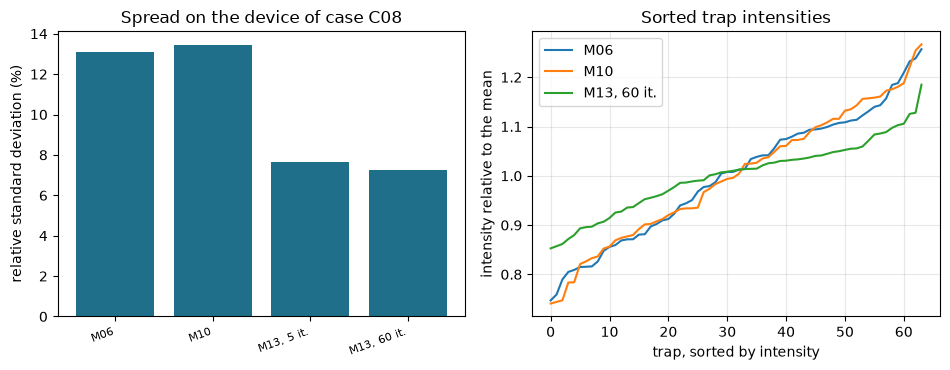

In [9]:
# relative standard deviation on the device for every hologram, and the sorted trap intensities of three of them
fig, (a, b) = plt.subplots(1, 2, figsize=(9.6, 3.8))
names = list(on_device)
a.bar(range(len(names)), [on_device[k]["rel_std_pct"] for k in names], color="#1f6f8b")
a.set_xticks(range(len(names)))
a.set_xticklabels(names, rotation=20, ha="right", fontsize=8)
a.set_ylabel("relative standard deviation (%)")
a.set_title("Spread on the device of case C08")
for name in ("M06", "M10", "M13, 60 it."):
    b.plot(np.sort(on_device[name]["trap_intensity"]), label=name)
b.set_xlabel("trap, sorted by intensity")
b.set_ylabel("intensity relative to the mean")
b.set_title("Sorted trap intensities")
b.legend()
b.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

M10 and M06 are at the same level, 13.45 and 13.07 percent, and the two M13 bars are at 7.65 and 7.27 percent: with the device in its model the conjugate gradient removes 46 percent of the spread that M10 leaves, with a uniformity of 0.8370 against 0.7380. In the sorted curves the traps of M13 lie between about 0.85 and 1.18 of the mean, against about 0.74 and 1.27 for M06 and M10, and its middle is flatter. It costs little light: the efficiency is 0.6824 against 0.6851, a loss of 0.0027. The figure is for one start, one seed and one device; the paper's disc is a different problem, and the notebook does not repeat it.

The last figure shows where the crosstalk-aware optimiser moved the hologram: the wrapped difference, pixel by pixel, between the phase pattern of M13 and the weighted-GS pattern it started from.

rms change 0.0778 rad | largest 0.357 rad
share of pixels above 0.1 rad: 0.190


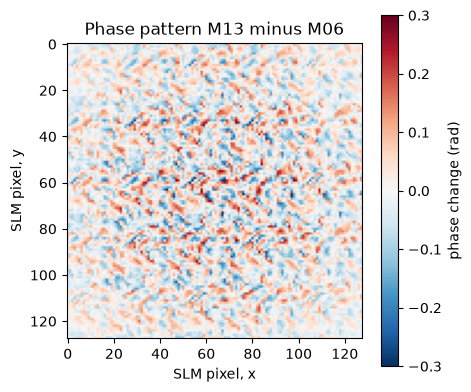

In [10]:
# what M13 changed in the hologram: the wrapped phase difference between the M13 and the M06 patterns
change = np.angle(np.exp(1j * (res13b.phi - res06.phi)))
print(f"rms change {np.sqrt(np.mean(change ** 2)):.4f} rad | largest {np.abs(change).max():.3f} rad")
print(f"share of pixels above 0.1 rad: {np.mean(np.abs(change) > 0.1):.3f}")
fig, ax = plt.subplots(figsize=(4.8, 4.2))
image = ax.imshow(change, cmap="RdBu_r", vmin=-0.3, vmax=0.3)
fig.colorbar(image, ax=ax, label="phase change (rad)")
ax.set_xlabel("SLM pixel, x")
ax.set_ylabel("SLM pixel, y")
ax.set_title("Phase pattern M13 minus M06")
plt.tight_layout()
plt.show()

The change is small and spread over the whole aperture: the rms is 0.0778 rad and the largest change 0.357 rad, and 19.0 percent of the pixels move by more than 0.1 rad. On a scale of plus and minus 0.3 rad the figure shows a fine pattern of alternating sign at the scale of a few pixels, strongest in the centre of the aperture, where the beam carries the most light, and fainter towards the edges. That is the whole difference between a hologram that shows 13.07 percent of spread on the device and one that shows 7.27 percent: a pre-distortion of a few hundredths of a radian per pixel, at the scale the crosstalk kernel blurs, which a plot of the patterns themselves could not reveal.

## Results

**Answer:** A conjugate-gradient optimiser with the crosstalk kernel in its model wins back part of what crosstalk costs, and the same optimiser on the ideal model wins back nothing. From the same weighted-GS start, on the device of case C08, M10 ends at a relative standard deviation of 13.45 percent against 13.07 for the start, while M13 reaches 7.65 percent in 5 iterations and 7.27 percent in 60, with a uniformity of 0.8370 (0.7380 for M10), removing 46 percent of the spread M10 leaves for 0.0027 of the light (an efficiency of 0.6824 against 0.6851). With no device in its model it equals M10 to 0.00e+00 rad. The floor it leaves is the quantizer and the flicker: the same optimiser run for the smooth device reaches 3.55 percent there and shows 6.63 percent on the full device, lower than the 7.27 of the full-model run, so the straight-through quantizer in the model does not pay on this case.

What the notebook does not show is the large disc of the paper, why the straight-through quantizer costs, or an independent implementation of M13, which does not exist among the dependencies.

## Summary

- M13 is M10 run on the focal field of the device: crosstalk kernel, pixel aperture and a straight-through quantizer, with the adjoint of the kernel in closed form.
- On the C08 device it cuts the spread from 13.45 percent (M10) to 7.27 percent in 60 iterations, for 0.0027 of the light, and most of the gain comes in its first 5 iterations.
- The rest of the floor is the quantizer and the flicker; leaving the quantizer out of the model does better on the full device here (6.63 percent).
- With no device it equals M10 exactly.
- No pinned reference implementation of M13 exists among the dependencies.

## References

- Schroff et al. (2023). Accurate holographic light potentials using pixel crosstalk modelling. Scientific Reports 13, 3252. https://doi.org/10.1038/s41598-023-30296-6
- Harte et al. (2014). A conjugate gradient minimisation approach to generating holographic traps for ultracold atoms. Optics Express 22, 26548. https://doi.org/10.1364/OE.22.026548